<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Skyrmion_Excitation_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

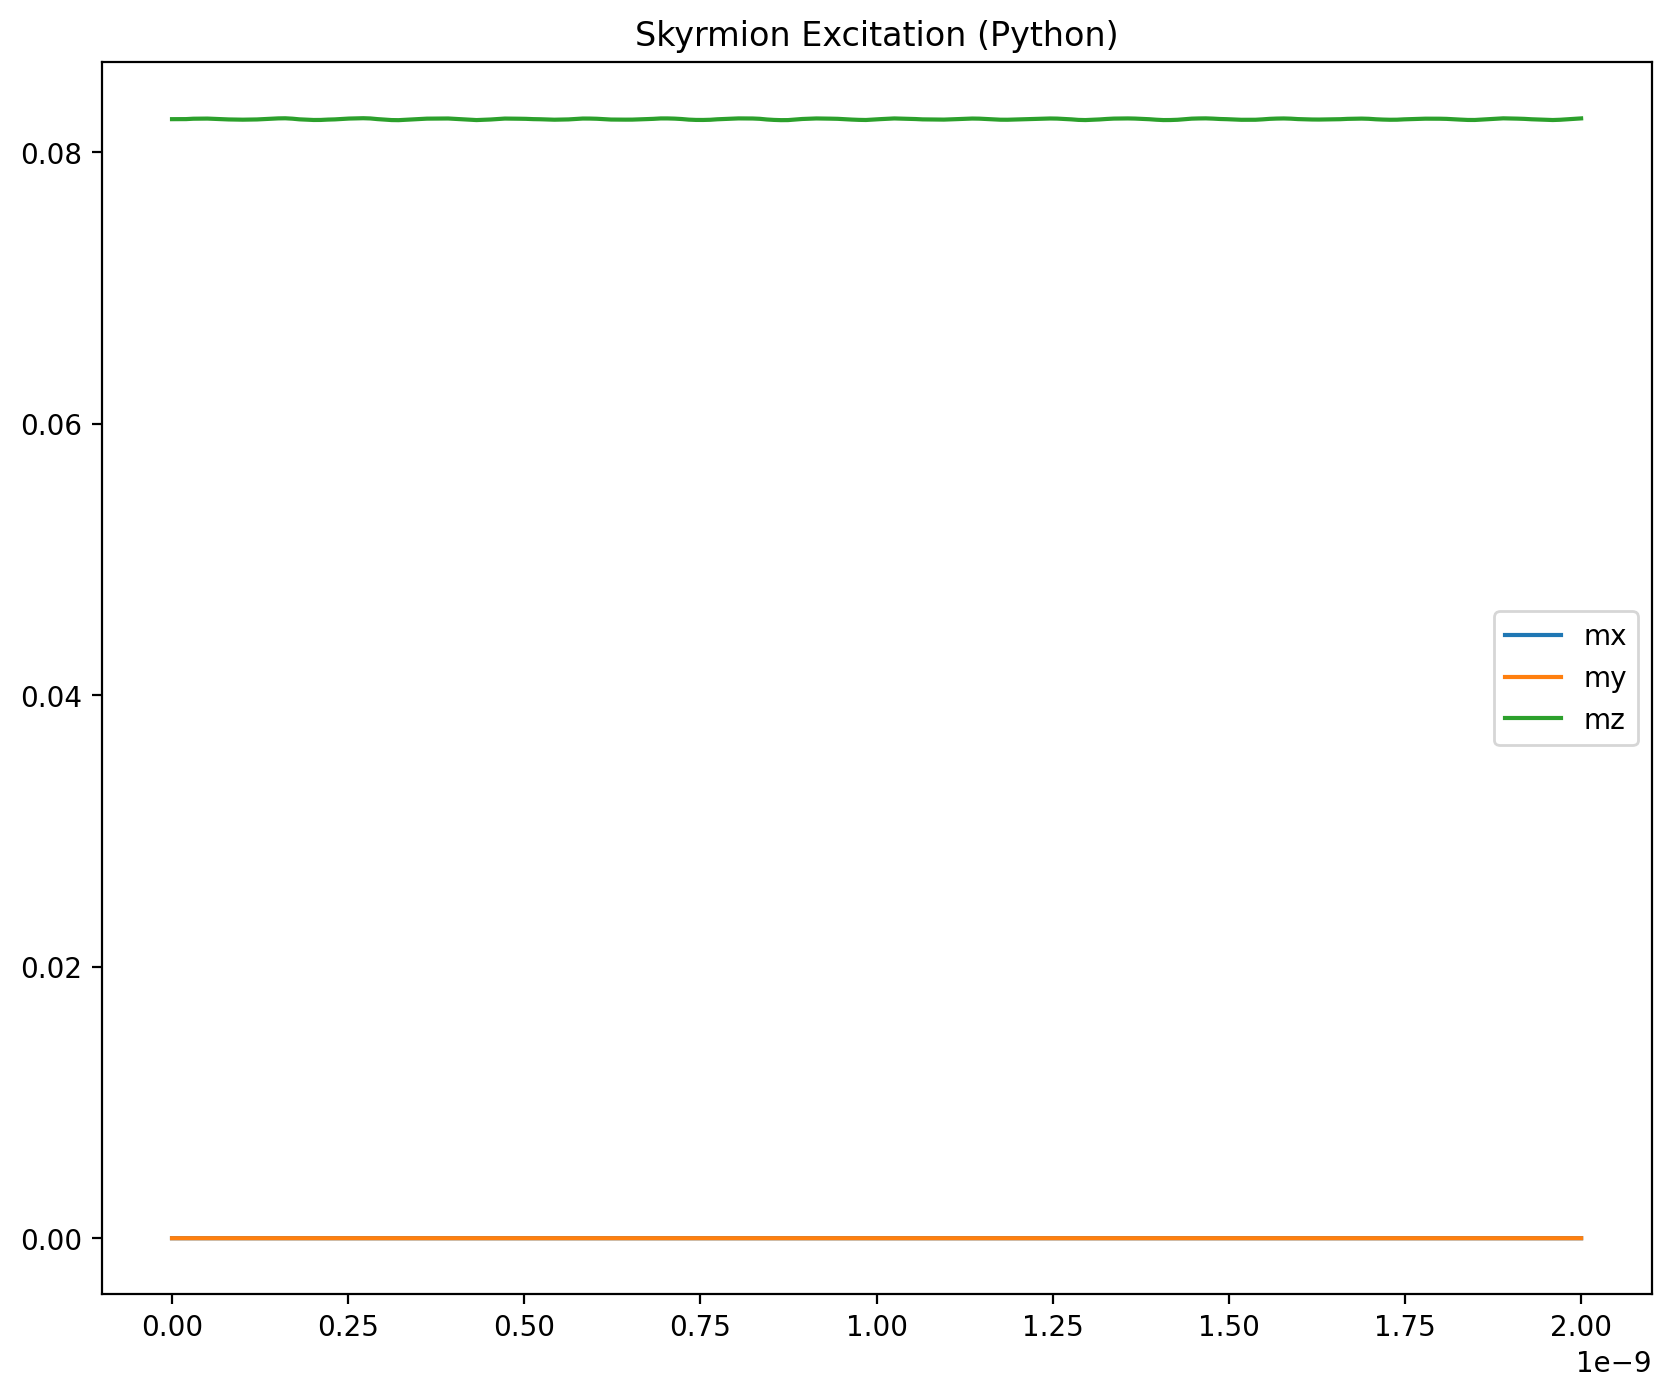

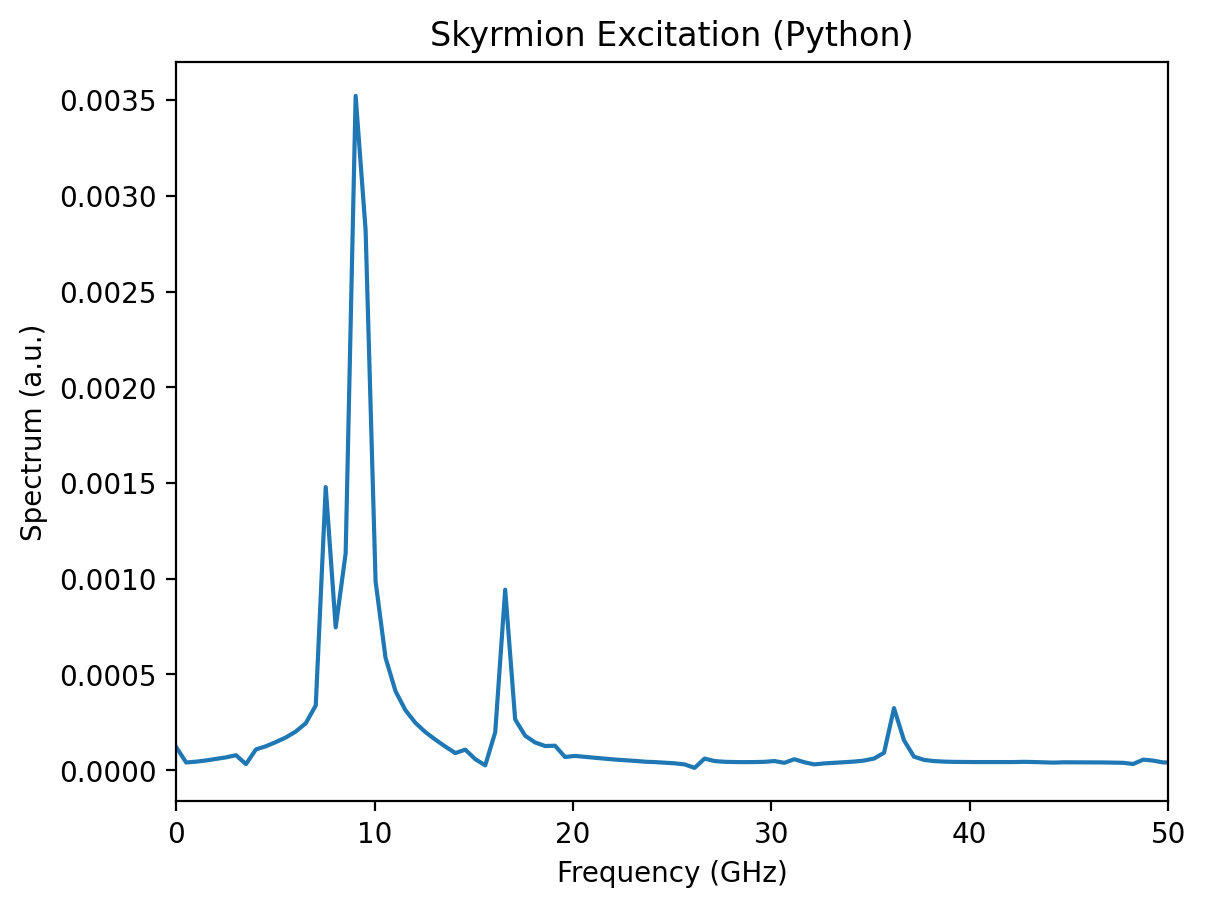

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import neelskyrmion

plt.rcParams["figure.dpi"] = 200

# NUMERICAL PARAMETERS RELEVANT FOR THE SPECTRUM ANALYSIS
fmax = 50E9           # maximum frequency (in Hz) of the sinc pulse
T = 2E-9              # simulation time (longer -> better frequency resolution)
dt = 1 / (2 * fmax)   # the sample time (Nyquist theorem taken into account)
t0 = 1 / fmax
d = 100E-9            # circle diameter
nx = 32               # number of cells


# CREATE THE WORLD
grid_size = (nx, nx, 1)
cell_size = (d / nx, d / nx, 1E-9)

world = World(cell_size)

# CREATE A FERROMAGNET
magnet = Ferromagnet(world, Grid(size=grid_size))
magnet.msat = 1E6
magnet.aex = 15E-12

magnet.ku1 = lambda t: 1E5 * (1 + 0.01 * np.sinc(2 * fmax * (t - t0)))

magnet.dmi_tensor.set_interfacial_dmi(3E-3)
magnet.anisU = (0, 0, 1)
magnet.alpha = 0.001

# SET AND RELAX INITIAL MAGNETIZATION
magnet.magnetization = neelskyrmion(position=magnet.center,
                                    radius=0.5 * d,
                                    charge=-1,
                                    polarization=1)
magnet.minimize()

timepoints = np.linspace(0, T, int(T / dt))
outputquantities = {
    'mx': lambda: magnet.magnetization.average()[0],
    'my': lambda: magnet.magnetization.average()[1],
    'mz': lambda: magnet.magnetization.average()[2],
}

# RUN THE SOLVER
output = world.timesolver.solve(timepoints, outputquantities)

# PLOT THE OUTPUT DATA
plt.figure(figsize=(10, 8))
for key in ['mx', 'my', 'mz']:
    plt.plot(output['time'], output[key], label=key)
plt.legend()
plt.title('Skyrmion Excitation (Python)')
plt.show()

# FAST FOURIER TRANSFORM
dm     = np.array(output['mz']) - output['mz'][0]   # average magnetization deviaton
spectr = np.abs(np.fft.fft(dm))         # the absolute value of the FFT of dm
freq   = np.linspace(0, 1/dt, len(dm))  # the frequencies for this FFT

# PLOT THE SPECTRUM
plt.plot(freq/1e9, spectr)
plt.xlim(0,fmax/1e9)
plt.ylabel('Spectrum (a.u.)')
plt.xlabel('Frequency (GHz)')
plt.title('Skyrmion Excitation (Python)')
plt.show()